# Projet ML kaggle : Give me some credits

## Remise en contexte : détailler + PROBLEMATIQUE

## 1. La mise en route
### 1.A Import des modules

In [1]:
# Imports des modules nécessaires

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split

### 1.B Import des données

In [2]:
# Imports du jeu de données cs-training.csv

df = pd.read_csv("cs-training.csv", index_col=0)
print("Taille du jeu de données :", df.shape)

# On regarde la proportion respectivement de 0 et 1 dans la colonne cible SeriousDlqin2yrs
print(df["SeriousDlqin2yrs"].value_counts(normalize=True))

Taille du jeu de données : (150000, 11)
SeriousDlqin2yrs
0    0.93316
1    0.06684
Name: proportion, dtype: float64


### 1.C Préparation des des données d'entraînement et de test

In [3]:
# Découpage du jeu de données cs-training.csv en un jeu d'entraînement et un jeu de test

X = df.drop(columns="SeriousDlqin2yrs")
y = df["SeriousDlqin2yrs"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(120000, 10) (30000, 10)
0.06684166666666666 0.06683333333333333


## 2. L'exploration des données
### 2.A Description générale du jeu de données train

In [4]:
train = X_train.copy()
train["SeriousDlqin2yrs"] = y_train

print("\nStructure des données de train : \n------------------")
train.info()                    # On repère notamment les valeurs manquantes et le type des variables
print("\nQuelques statistiques descriptives : \n------------------")
train.describe().T


Structure des données de train : 
------------------
<class 'pandas.core.frame.DataFrame'>
Index: 120000 entries, 57837 to 80531
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   RevolvingUtilizationOfUnsecuredLines  120000 non-null  float64
 1   age                                   120000 non-null  int64  
 2   NumberOfTime30-59DaysPastDueNotWorse  120000 non-null  int64  
 3   DebtRatio                             120000 non-null  float64
 4   MonthlyIncome                         96325 non-null   float64
 5   NumberOfOpenCreditLinesAndLoans       120000 non-null  int64  
 6   NumberOfTimes90DaysLate               120000 non-null  int64  
 7   NumberRealEstateLoansOrLines          120000 non-null  int64  
 8   NumberOfTime60-89DaysPastDueNotWorse  120000 non-null  int64  
 9   NumberOfDependents                    116872 non-null  float64
 10  SeriousDlqin2yrs

,count,mean,std,min,25%,50%,75%,max
RevolvingUtilizationOfUnsecuredLines,120000.0,6.128916,253.361490,0.0,0.029593,0.153318,0.557832,50708.0
age,120000.0,52.287842,14.771274,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,120000.0,0.420075,4.182138,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,120000.0,352.271245,2093.709509,0.0,0.175330,0.366194,0.860833,329664.0
MonthlyIncome,96325.0,6651.507345,14541.181413,0.0,3400.000000,5390.000000,8238.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,120000.0,8.465692,5.161693,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,120000.0,0.264942,4.158242,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,120000.0,1.018167,1.133055,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,120000.0,0.239858,4.144569,0.0,0.000000,0.000000,0.000000,98.0
NumberOfDependents,116872.0,0.757333,1.115337,0.0,0.000000,0.000000,1.000000,20.0


### 2.B Description des valeurs manquantes

In [5]:
print("\nProportion de valeurs manquantes dans chaque variable du jeu de données train : \n------------------")
missing = train.isna().mean().sort_values(ascending=False) * 100
print(missing[missing > 0].round(2))

# On regarde la proportion de défauts de paiement en fonction des variables avec valeurs manquantes
print("\nLes manquants sont-ils corrélés avec la variable cible ? \n------------------")
for i in ["MonthlyIncome", "NumberOfDependents"]:
    taux = train.groupby(train[i].isna())["SeriousDlqin2yrs"].mean()
    print(i, "\n", taux.rename({False: "renseigné", True: "manquant"}), "\n")



Proportion de valeurs manquantes dans chaque variable du jeu de données train : 
------------------
MonthlyIncome         19.73
NumberOfDependents     2.61
dtype: float64

Les manquants sont-ils corrélés avec la variable cible ? 
------------------
MonthlyIncome 
 MonthlyIncome
renseigné    0.069577
manquant     0.055713
Name: SeriousDlqin2yrs, dtype: float64 

NumberOfDependents 
 NumberOfDependents
renseigné    0.067450
manquant     0.044118
Name: SeriousDlqin2yrs, dtype: float64 



<div style="color: #eb65f0;">

##### Ce qu'on observe : 2 variables contiennent des valeurs manquantes

- Près de 20% des personnes n'ont pas renseigné leur revenu mensuel (MonthlyIncome)
- On a 2,6% de valeurs manquantes sur le nombre de personnes à charge (NumberOfDependents)

##### Comment interpréter les valeurs manquantes ?

On calcule le taux de défaut de paiement dans chaque groupe qui contient des manquants.
On remarque cependant qu'on ne peut pas conclure sur l'association entre l'absence de revenus indiquée et un potentiel défaut de paiement.

</div>


### 2.C Analyse des valeurs suspectes

In [6]:
print("Âge < 18 ans :", (train["age"] <18 ).sum())
for col in ["RevolvingUtilizationOfUnsecuredLines", "DebtRatio"]:
    valeurs = train[train[col] > 1][col]
    print(col, "/ nombre :", len(valeurs), "/ moyenne :", round(valeurs.mean(), 2), "/ médiane :", round(valeurs.median(), 2))

retards = ["NumberOfTime30-59DaysPastDueNotWorse",
           "NumberOfTimes90DaysLate",
           "NumberOfTime60-89DaysPastDueNotWorse"]
for c in retards:
    print(c, train[c].value_counts().sort_index().tail(6).to_dict())

print("Doublons :", train.duplicated().sum())

Âge < 18 ans : 1
RevolvingUtilizationOfUnsecuredLines / nombre : 2640 / moyenne : 265.11 / médiane : 1.08
DebtRatio / nombre : 27987 / moyenne : 1509.44 / médiane : 913.0
NumberOfTime30-59DaysPastDueNotWorse {10: 4, 11: 1, 12: 2, 13: 1, 96: 2, 98: 212}
NumberOfTimes90DaysLate {13: 3, 14: 2, 15: 2, 17: 1, 96: 2, 98: 212}
NumberOfTime60-89DaysPastDueNotWorse {7: 8, 8: 1, 9: 1, 11: 1, 96: 2, 98: 212}
Doublons : 437


<div style="color: #eb65f0;">

##### Ce qu'on observe : certaines données qui attirent l'attention
- Des clients qui seraient mineurs : cela pourrait être soit une erreur de saisie, soit une donnée manquante pour l'âge remplacée par un 0

- **Le ratio d'utilisation de crédit > 1** : n'est pas alarmant en soi, mais pourrait être un indicateur pour l'interprétation des résultats plus tard. On remarque des données très aberrantes avec une moyenne 265 fois supérieure à la médiane, donc tirée par ces valeurs aberrantes.

- **Le ratio de dette > 1** : n'est pas non plus alarmant en soi, mais comme ce ratio dépend du revenu mensuel pour lequel on a beaucoup de données manquantes (20%), il faut rester vigilant aux erreurs de calcul. Ici ce n'est pas une anomalie rare car plus de 27000 lignes la contiennent, soit presque 20% du nombre de lignes tout comme le nombre de données manquantes en MonthlyIncome : on a donc des aberrations sur le ratio de dettes à cause des données manquantes de MonthlyIncome et des données = 0.

##### Les retards de paiement
- Concernant les retards : certains chiffres très élevés comme 96 ou 98 apparaissant près de 214 fois par variables peuvent représenter des anomalies de saisie ou de calcul, ou bien codes à déchiffrer lors de l'apprentissage. Il est assez étrange d'avoir un client ayant dépassé 96 ou 98 fois les 30 jours de retards de paiement en 2 ans.

##### Les doublons
On a 437 doublons qui peuvent fausser les données. Cependant plusieurs clients peuvent avoir les mêmes lignes descriptives.

</div>

### 2.D Etude des distributions graphiques des données

##### On peut maintenant visualiser de plus près ce que donne la distribution de nos données

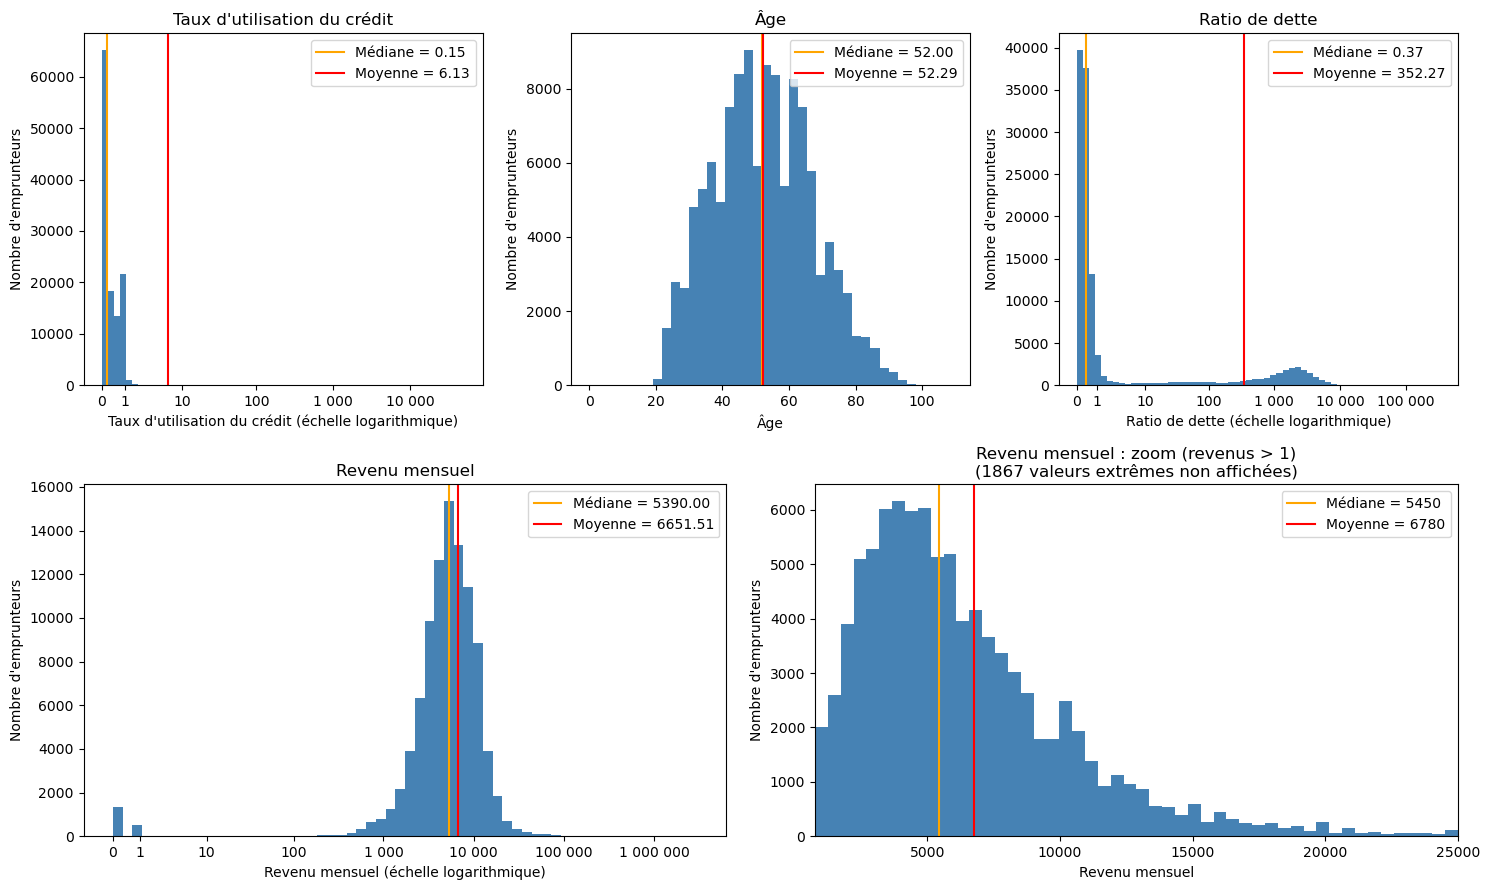

In [15]:
variables = {
    "RevolvingUtilizationOfUnsecuredLines": "Taux d'utilisation du crédit",
    "age": "Âge",
    "DebtRatio": "Ratio de dette",
    "MonthlyIncome": "Revenu mensuel",
}

variables_log = ["RevolvingUtilizationOfUnsecuredLines", "DebtRatio", "MonthlyIncome"]   # tout sauf l'âge

# Grille de 2 lignes x 6 colonnes : 3 graphiques en haut, 2 en bas
fig = plt.figure(figsize=(15, 9))
grille = fig.add_gridspec(2, 6)
emplacements = [grille[0, 0:2], grille[0, 2:4], grille[0, 4:6], grille[1, 0:3]]
axes = [fig.add_subplot(e) for e in emplacements]
ax_zoom = fig.add_subplot(grille[1, 3:6])

for ax, (col, nom) in zip(axes, variables.items()):
    valeurs = train[col].dropna()
    mediane = valeurs.median()
    moyenne = valeurs.mean()

    if col in variables_log:
        ax.hist(np.log1p(valeurs), bins=60, color="steelblue")
        position_mediane, position_moyenne = np.log1p(mediane), np.log1p(moyenne)

        # On remplace les graduations (valeurs du log) par les valeurs réelles correspondantes
        reels = [0, 1, 10, 100, 1000, 10000, 100000, 1000000]
        reels = [r for r in reels if r <= valeurs.max()]       # on garde seulement celles qui existent dans les données
        ax.set_xticks(np.log1p(reels))
        ax.set_xticklabels([f"{r:,}".replace(",", " ") for r in reels])
        ax.set_xlabel(f"{nom} (échelle logarithmique)")
    else:
        ax.hist(valeurs, bins=40, color="steelblue")
        position_mediane, position_moyenne = mediane, moyenne
        ax.set_xlabel(nom)

    ax.axvline(position_mediane, color="orange", label=f"Médiane = {mediane:.2f}")
    ax.axvline(position_moyenne, color="red", label=f"Moyenne = {moyenne:.2f}")
    ax.set_title(nom)
    ax.set_ylabel("Nombre d'emprunteurs")
    ax.legend()

# Zoom sur le revenu mensuel, échelle normale
revenus = train["MonthlyIncome"].dropna()
revenus = revenus[revenus > 1]                      # on retire les revenus 0 et 1 (valeurs suspectes)
mediane_zoom = revenus.median()
moyenne_zoom = revenus.mean()

bas = revenus.quantile(0.01)
haut = revenus.quantile(0.99)
nb_exclus = ((revenus < bas) | (revenus > haut)).sum()

ax_zoom.hist(revenus, bins=50, range=(bas, haut), color="steelblue")
ax_zoom.axvline(mediane_zoom, color="orange", label=f"Médiane = {mediane_zoom:.0f}")
ax_zoom.axvline(moyenne_zoom, color="red", label=f"Moyenne = {moyenne_zoom:.0f}")
ax_zoom.set_xlim(bas, haut)
ax_zoom.set_title(f"Revenu mensuel : zoom (revenus > 1)\n({nb_exclus} valeurs extrêmes non affichées)")
ax_zoom.set_xlabel("Revenu mensuel")
ax_zoom.set_ylabel("Nombre d'emprunteurs")
ax_zoom.legend()

plt.tight_layout()
plt.show()

##### Ce qu'on observe

**Ce qui est tracé.** Pour chaque variable, un histogramme (nombre d'emprunteurs par plage de valeurs),
avec la médiane (orange) et la moyenne (rouge). Le taux d'utilisation du crédit, le ratio de dette et le
revenu sont en **échelle logarithmique** : quelques valeurs énormes écraseraient sinon tout le graphique.
Les graduations affichent les vraies valeurs, et chaque pas correspond à une multiplication par 10.

##### Taux d'utilisation du crédit
- **Observation** : la majorité des valeurs est entre 0 et 1. Médiane = […], moyenne = […].
  2 640 lignes dépassent 1.
- **Interprétation** : un taux légèrement supérieur à 1 est possible (dépassement de la limite), mais les
  valeurs énormes sont suspectes. Elles tirent la moyenne bien au-dessus de la médiane.
- **Décision** : plafonner ces valeurs extrêmes dans le pipeline.

##### Âge
- **Observation** : […forme de la distribution, plage principale…]. Une seule ligne avec age < 18.
- **Interprétation** : variable propre, sans valeur extrême problématique.
- **Décision** : rien de particulier, on ignore la ligne aberrante.

##### Ratio de dette
- **Observation** : […]. 27 987 lignes ont un ratio supérieur à 1.
- **Interprétation** : trop de lignes pour de simples erreurs. Hypothèse : le ratio devient énorme quand
  le revenu est manquant, 0 ou 1 (à confirmer avec le tableau croisé).
- **Décision** : à fixer après ce test.

##### Revenu mensuel
- **Observation** : médiane = 5 390, moyenne = 6 651. La majorité des emprunteurs se situe entre
  quelques milliers et 10 000. Deux petites barres isolées, à 0 et à 1.
- **Interprétation** : un revenu de 1 par mois est très suspect, probablement une valeur de remplissage.
  Le zoom (sans log, revenus > 1) montre une distribution asymétrique avec une longue traîne à droite,
  que le log rendait presque symétrique.
- **Décision** : traiter les revenus ≤ 1 comme manquants, avec une colonne « revenu non fiable »
  (19,7 % de manquants au total).

##### Conclusion
Trois variables sont dominées par des valeurs extrêmes ou suspectes. On corrigera cela dans le pipeline
(étape 5), en apprenant les transformations sur le train seulement.

## 3. Nettoyage des données et baseline

In [25]:
def nettoyer(df):
    df = df.copy()                                            # on travaille sur une copie, pour ne pas toucher à l'original

    colonnes_retards = ["NumberOfTime30-59DaysPastDueNotWorse",
                        "NumberOfTime60-89DaysPastDueNotWorse",
                        "NumberOfTimes90DaysLate"]
    for col in colonnes_retards:
        df.loc[df[col] >= 96, col] = np.nan                   # les codes 96 et 98 sont des valeurs spéciales

    df.loc[df["MonthlyIncome"] <= 1, "MonthlyIncome"] = np.nan   # revenus 0 ou 1 : pas fiables
    df.loc[df["age"] < 18, "age"] = np.nan                    # âge impossible
    return df.drop(columns=["Unnamed: 0", "tranche_age"], errors="ignore")   # on retire l'identifiant et la colonne de tranches d'âge

train_propre = nettoyer(train)
print(train_propre.isna().sum())

RevolvingUtilizationOfUnsecuredLines        0
age                                         1
NumberOfTime30-59DaysPastDueNotWorse      214
DebtRatio                                   0
MonthlyIncome                           25495
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                   214
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse      214
NumberOfDependents                       3128
SeriousDlqin2yrs                            0
dtype: int64


### Les données nettoyées : ...

In [26]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate

X = train_propre.drop(columns=["SeriousDlqin2yrs"])     # les variables
y = train_propre["SeriousDlqin2yrs"]                    # la cible (défaut ou non)

validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metriques = ["accuracy", "roc_auc", "average_precision"]

modeles = {
    "Toujours « pas de défaut »": DummyClassifier(strategy="most_frequent"),
    "Régression logistique simple": make_pipeline(
        SimpleImputer(strategy="median", add_indicator=True),   # remplace les manquants par la médiane
        StandardScaler(),                                       # met les variables à la même échelle
        LogisticRegression(max_iter=1000),
    ),
}

resultats = {}
for nom, modele in modeles.items():
    scores = cross_validate(modele, X, y, cv=validation, scoring=metriques)
    resultats[nom] = {m: scores[f"test_{m}"].mean() for m in metriques}

print(pd.DataFrame(resultats).T.round(3))

                              accuracy  roc_auc  average_precision
Toujours « pas de défaut »       0.933    0.500              0.067
Régression logistique simple     0.936    0.814              0.352


In [27]:
from sklearn.metrics import roc_auc_score

force = {}
for col in X.columns:
    score = X[col].fillna(X[col].median())       # les manquants sont remplacés par la médiane, pour ce calcul seulement
    auc = roc_auc_score(y, score)
    force[col] = max(auc, 1 - auc)               # si auc < 0.5, la variable agit en sens inverse : on la retourne

print(pd.Series(force).sort_values(ascending=False).round(3))

RevolvingUtilizationOfUnsecuredLines    0.778
NumberOfTime30-59DaysPastDueNotWorse    0.680
NumberOfTimes90DaysLate                 0.651
age                                     0.632
NumberOfTime60-89DaysPastDueNotWorse    0.616
MonthlyIncome                           0.576
NumberOfDependents                      0.548
NumberOfOpenCreditLinesAndLoans         0.547
NumberRealEstateLoansOrLines            0.537
DebtRatio                               0.522
dtype: float64


commentaire :
- Les premières variables importantes pour décrire, on voit un intérêt d'en combiner certaines car le modèle a une meilleure perf que elles séparées
- debtratio notament presque variable inutile on dirait alors que cela relève + de l'anomalie que d'une variable inutile

In [ ]:
# Cellule 1 : le ratio de dette selon que le revenu est exploitable ou non
groupe_revenu = np.where(train_propre["MonthlyIncome"].isna(), "Revenu manquant ou ≤ 1", "Revenu > 1")

resume = train_propre.groupby(groupe_revenu).agg(
    nb_lignes=("DebtRatio", "size"),
    part_debtratio_sup_1=("DebtRatio", lambda s: (s > 1).mean() * 100),
    debtratio_median=("DebtRatio", "median"),
    taux_defaut=("SeriousDlqin2yrs", "mean"),)
resume["taux_defaut"] *= 100
print(resume.round(2))

# Cellule 2 : le DebtRatio est-il utile quand le revenu est fiable ?
fiable = train_propre[train_propre["MonthlyIncome"].notna()]
print("AUC du DebtRatio avec revenu fiable :", round(roc_auc_score(fiable["SeriousDlqin2yrs"], fiable["DebtRatio"]), 3))

                        nb_lignes  part_debtratio_sup_1  debtratio_median  \
Revenu > 1                  94505                  4.33              0.29   
Revenu manquant ou ≤ 1      25495                 93.71           1131.00   

                        taux_defaut  
Revenu > 1                     7.02  
Revenu manquant ou ≤ 1         5.44  
AUC du DebtRatio avec revenu fiable : 0.567
